# 2차 팀 프로젝트 개발 (1) — Streamlit 대시보드 `app.py` 의 계산을 노트북으로 따라가기

2팀 프로젝트 **ShopInsight** 의 대시보드 코드 `team_project/app.py` 가 화면 뒤에서 하는 계산(데이터 집계 · 전처리 · MLP 예측 · 성능 평가)을 **Streamlit 없이 한 줄씩 다시 실행**하며 정리 · 점검한 노트입니다.

- 원본 : [`team_project/`](./team_project/) — `app.py`(최종본) · `app_v1.py`(초기본) · `requirements.txt` · `.streamlit/config.toml` · `data/` · `models/` ([팀 저장소](https://github.com/SKNETWORKS-FAMILY-AICAMP/SKN37-2ST-2TEAM))
- 두 버전의 차이는 [`app_version_changes.ipynb`](./app_version_changes.ipynb), 데이터 · 모델 분석은 [Day 038 (11-02)](../../2026-11-02/lecture/) 에 이어집니다.
- 짚어 볼 부분은 **📝 점검** 으로 따로 적었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 앱 구조 — 파일 3개 · 페이지 4개

| 페이지 | 쓰는 것 | 핵심 함수 |
|---|---|---|
| 핵심 지표 | CSV | `load_data` · `create_analysis_tables` (멤버십 · 포인트 구간) |
| 고객 이탈 예측 | 모델 + 전처리기 | `ChurnMLP.predict_proba` (입력 폼 5개) |
| 이탈 원인 분석 | CSV | 피드백 · 거래 금액 구간 · 로그인 간격 · 히트맵 |
| 모델 성능 | CSV + 모델 | `evaluate_mlp` (정확도 · 재현율 · F1 · AUC · 혼동 행렬 · ROC) |

| Streamlit 기능 | `app.py` 에서 하는 일 |
|---|---|
| `@st.cache_data` | CSV 읽기 · 집계 · 성능 계산 결과를 저장 — 파일 수정 시각(`st_mtime`)을 인자로 넣어 **파일이 바뀌면 다시 계산** |
| `@st.cache_resource` + `threading.Thread` | PyTorch 로딩(몇 초)을 **백그라운드**에서 한 번만 → 요약 · 분석 화면은 기다리지 않음 |
| `st.fragment(run_every=0.5)` | 사이드바 '모델 불러오는 중…' 부분만 0.5초마다 다시 그려 '연결됨' 으로 바꿈 |
| `st.session_state` · `st.query_params` | 현재 페이지 기억 · 새로고침해도 같은 페이지 |
| `st.form` | 입력 5개를 다 채우고 버튼을 눌렀을 때만 예측 (입력할 때마다 다시 실행되지 않게) |
| `st.html` vs `st.markdown` | `st.html` 이 빠르지만 `<svg>` 를 지워서 그래프 블록만 `st.markdown` |

![앱 흐름 애니메이션](./images/anim_01_app_flow.gif)

## 2. 데이터 불러오기 · 핵심 지표 (KPI)

In [2]:
import numpy as np
import pandas as pd

DATA = 'team_project/data/[2nd] customer_churn_ecommerce_cleaned.csv'
REQUIRED_DATA_COLUMNS = {'membership_category', 'points_in_wallet', 'feedback', 'avg_transaction_value',
                         'avg_frequency_login_days', 'avg_time_spent', 'churn_risk_score'}

def load_data(path):
    data = pd.read_csv(path)
    missing = REQUIRED_DATA_COLUMNS.difference(data.columns)       # 필요한 열이 빠졌으면 바로 알려 주기
    if missing:
        raise ValueError(f'CSV에 필요한 컬럼이 없습니다: {", ".join(sorted(missing))}')
    return data

data = load_data(DATA)
TARGET = 'churn_risk_score'
row_count = len(data)
label_rate = data[TARGET].mean() * 100
feature_count = len([c for c in data.columns if c != TARGET])
print(f'분석 고객 수 {row_count:,}명 · 이탈 라벨 비율 {label_rate:.1f}% · 특성 {feature_count}개 · 결측 {data.isna().sum().sum()}개')

분석 고객 수 36,992명 · 이탈 라벨 비율 54.1% · 특성 22개 · 결측 0개


## 3. 집계 — `create_analysis_tables` 다시 실행

In [3]:
POSITIVE_FEEDBACK = {'Products always in Stock', 'Quality Customer Care', 'Reasonable Price', 'User Friendly Website'}
QLABELS = ['하위 25%', '중하위 25%', '중상위 25%', '상위 25%']

def rate_table(df, col):
    r = df.groupby(col, dropna=False)[TARGET].agg(customers='size', rate='mean').reset_index()
    r['rate_pct'] = r['rate'] * 100
    return r

def quartile_series(series, labels=QLABELS):
    # app.py : 같은 값이 많아도 정확히 4등분하려고 '순위' 로 나눔
    ranks = pd.to_numeric(series, errors='coerce').rank(method='first')
    return pd.qcut(ranks, q=4, labels=labels)

def group_rate(bins):
    g = pd.DataFrame({'구간': bins, TARGET: data[TARGET]}).groupby('구간', observed=False)[TARGET]
    return g.agg(customers='size', rate='mean').assign(rate_pct=lambda t: t['rate'] * 100)

membership = rate_table(data, 'membership_category').sort_values('rate', ascending=False)
points = group_rate(quartile_series(data['points_in_wallet']))
transaction = group_rate(quartile_series(data['avg_transaction_value']))
LOGIN = ['1–4일', '5–8일', '9–14일', '15일 이상']
login_bins = pd.cut(pd.to_numeric(data['avg_frequency_login_days'], errors='coerce'),
                    bins=[-np.inf, 4, 8, 14, np.inf], labels=LOGIN)
login = group_rate(login_bins)

fb = rate_table(data, 'feedback')
pos = fb[fb['feedback'].isin(POSITIVE_FEEDBACK)]
feedback = pd.concat([fb[~fb['feedback'].isin(POSITIVE_FEEDBACK)][['feedback', 'customers', 'rate_pct']],
                      pd.DataFrame([{'feedback': '긍정 피드백 전체', 'customers': pos['customers'].sum(),
                                     'rate_pct': (pos['rate'] * pos['customers']).sum() / pos['customers'].sum() * 100}])]
                     ).sort_values('rate_pct', ascending=False)

for name, t in [('회원 등급', membership.set_index('membership_category')), ('포인트 구간', points),
                ('피드백', feedback.set_index('feedback')), ('거래 금액 구간', transaction), ('로그인 간격', login)]:
    print(f'[{name}]', {k: f'{v:.1f}%' for k, v in t['rate_pct'].items()})

[회원 등급] {'No Membership': '97.1%', 'Basic Membership': '96.8%', 'Silver Membership': '42.8%', 'Gold Membership': '37.0%', 'Platinum Membership': '0.0%', 'Premium Membership': '0.0%'}
[포인트 구간] {'하위 25%': '83.2%', '중하위 25%': '88.6%', '중상위 25%': '26.6%', '상위 25%': '18.0%'}
[피드백] {'Poor Product Quality': '65.0%', 'Poor Customer Service': '63.9%', 'No reason specified': '63.5%', 'Poor Website': '63.2%', 'Too many ads': '62.7%', '긍정 피드백 전체': '0.0%'}
[거래 금액 구간] {'하위 25%': '59.1%', '중하위 25%': '58.5%', '중상위 25%': '58.1%', '상위 25%': '40.6%'}
[로그인 간격] {'1–4일': '5.3%', '5–8일': '51.0%', '9–14일': '51.3%', '15일 이상': '58.2%'}


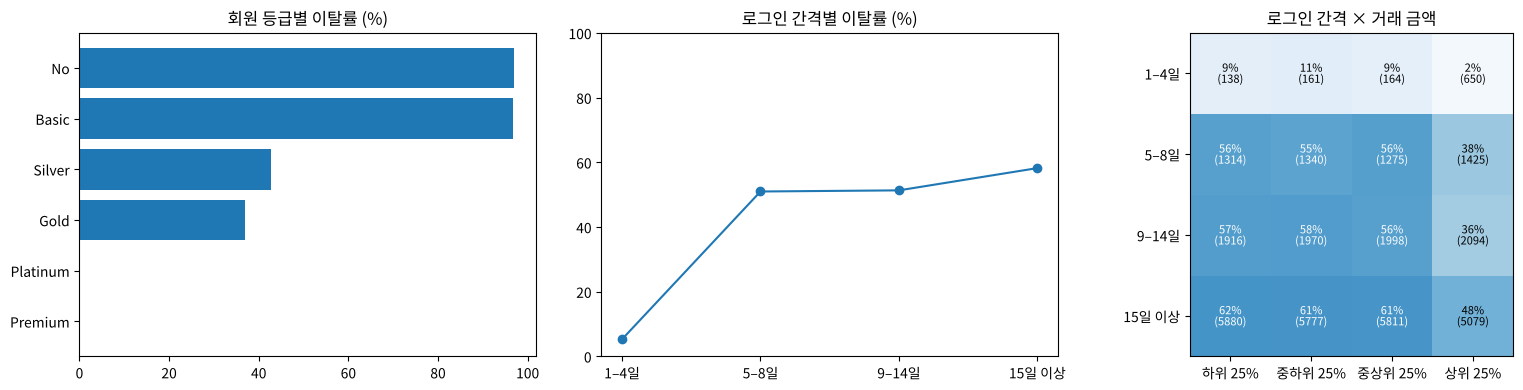

In [4]:
heat_df = pd.DataFrame({'login': login_bins, 'transaction': quartile_series(data['avg_transaction_value']), TARGET: data[TARGET]})
heat = heat_df.pivot_table(index='login', columns='transaction', values=TARGET, aggfunc='mean', observed=False) * 100
heat_n = heat_df.pivot_table(index='login', columns='transaction', values=TARGET, aggfunc='count', observed=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t = membership.set_index('membership_category')['rate_pct'].sort_values()
axes[0].barh([s.replace(' Membership', '') for s in t.index], t.values, color='tab:blue'); axes[0].set_title('회원 등급별 이탈률 (%)')
axes[1].plot(LOGIN, login['rate_pct'].values, marker='o'); axes[1].set_ylim(0, 100); axes[1].set_title('로그인 간격별 이탈률 (%)')
im = axes[2].imshow(heat.values, cmap='Blues', vmin=0, vmax=100)
axes[2].set_xticks(range(4), heat.columns); axes[2].set_yticks(range(4), heat.index); axes[2].set_title('로그인 간격 × 거래 금액')
for i in range(4):
    for j in range(4):
        axes[2].text(j, i, f'{heat.values[i, j]:.0f}%\n({int(heat_n.values[i, j])})', ha='center', va='center', fontsize=8,
                     color='white' if heat.values[i, j] > 50 else 'black')
plt.tight_layout(); plt.show()

대시보드의 '이탈 원인 분석' 페이지와 같은 숫자. 히트맵에서는 **로그인 1–4일**(1,113명) 행만 이탈률이 낮고 거래 금액 **상위 25%** 열이 전체적으로 낮다.

![히트맵 애니메이션](./images/anim_04_heatmap.gif)

## 4. 📝 점검 — 같은 값이 많은 열의 4분위

In [5]:
p = data['points_in_wallet']
tied = p == 697.62
q_rank = quartile_series(p)
print(f'697.62 (중앙값으로 채운 값) : {tied.sum():,}명')
print('순위 4분위에서 이들이 들어간 구간 :', q_rank[tied].value_counts().to_dict())

# 행 순서만 섞어서 다시 계산하면?
for seed in [0, 1, 2]:
    shuffled = data.sample(frac=1, random_state=seed)
    qs = pd.qcut(shuffled['points_in_wallet'].rank(method='first'), 4, labels=QLABELS)
    print(f'행 순서 섞기 {seed} →', shuffled.groupby(qs, observed=False)[TARGET].mean().mul(100).round(1).to_dict())

q_raw = pd.qcut(p, 4, labels=QLABELS)                       # 값 기준 : 같은 값은 같은 구간
print('값 기준 4분위 :', group_rate(q_raw)[['customers', 'rate_pct']].round(1).to_dict('index'))

697.62 (중앙값으로 채운 값) : 3,446명
순위 4분위에서 이들이 들어간 구간 : {'중하위 25%': 1724, '중상위 25%': 1722, '하위 25%': 0, '상위 25%': 0}
행 순서 섞기 0 → {'하위 25%': 83.2, '중하위 25%': 88.2, '중상위 25%': 27.0, '상위 25%': 18.0}
행 순서 섞기 1 → {'하위 25%': 83.2, '중하위 25%': 88.6, '중상위 25%': 26.6, '상위 25%': 18.0}
행 순서 섞기 2 → {'하위 25%': 83.2, '중하위 25%': 88.1, '중상위 25%': 27.1, '상위 25%': 18.0}
값 기준 4분위 : {'하위 25%': {'customers': 9249, 'rate_pct': 83.2}, '중하위 25%': {'customers': 10969, 'rate_pct': 83.0}, '중상위 25%': {'customers': 7526, 'rate_pct': 20.5}, '상위 25%': {'customers': 9248, 'rate_pct': 18.0}}


- `rank(method='first')` 는 같은 값을 **CSV 에 나온 순서대로** 다른 순위로 매긴다 → 697.62 인 3,446명이 '중하위' 1,724명 · '중상위' 1,722명으로 **임의로 갈린다**. 행 순서를 섞으면 두 구간의 이탈률이 조금씩 바뀐다(위 결과는 행 순서만 바꾼 것)
- 값 기준(`pd.qcut(p, 4)`)으로 나누면 같은 포인트는 같은 구간이 되지만 인원이 10,969 · 7,526 으로 달라진다 → 대시보드에는 **'구간 경계값(624 · 698 · 757점)'** 을 함께 적어 주면 해석이 쉽다
- `avg_frequency_login_days` 도 16.0 에 5,524명이 몰려 있고(중앙값 대체로 보임), README 에서 '정확한 정의 미확인' 인 열을 화면에서는 **'로그인 간격(일)'** 로 단정해 보여 준다

![4분위 애니메이션](./images/anim_03_rank_qcut.gif)

## 5. 모델 — `ChurnMLP` 다시 만들기

`app.py` 는 저장된 전처리기(`.pkl`, scikit-learn 1.6.1)를 다른 버전에서 `transform()` 하면 오류가 나서, **통계값(중앙값 · 평균 · 표준편차 · 범주 목록)만 꺼내 NumPy 로 같은 변환**을 한다. 여기서는 pickle 을 열지 않고(열 때 코드가 실행될 수 있음) **같은 분할로 전처리기를 다시 fit** 한 통계를 넣어, NumPy 변환이 scikit-learn 과 같은지 확인한다.

In [6]:
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

FEATURES = ['membership_category', 'points_in_wallet', 'avg_transaction_value', 'feedback_group']
NUM, CAT = ['points_in_wallet', 'avg_transaction_value'], ['membership_category', 'feedback_group']
feedback_mapping = {f: 'positive' for f in POSITIVE_FEEDBACK}
feedback_mapping.update({'No reason specified': 'none', 'Poor Product Quality': 'negative', 'Poor Customer Service': 'negative',
                         'Poor Website': 'negative', 'Too many ads': 'negative'})

def prepare_model_input(df):
    # app.py : 정제 CSV 에서 모델 입력 4개 만들기 (feedback → feedback_group)
    return pd.DataFrame({'membership_category': df['membership_category'].astype('object'),
                         'points_in_wallet': pd.to_numeric(df['points_in_wallet'], errors='coerce'),
                         'avg_transaction_value': pd.to_numeric(df['avg_transaction_value'], errors='coerce'),
                         'feedback_group': df['feedback'].map(feedback_mapping)}, index=df.index)

x, y = prepare_model_input(data), data[TARGET].astype(int)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)   # app.py 와 같은 분할

pre = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT),
]).fit(x_train)

In [7]:
class ChurnMLP:
    """app.py 의 ChurnMLP 와 같은 계산 (전처리 통계는 인자로 받음)"""

    def __init__(self, model_path, pre):
        ckpt = torch.load(model_path, map_location='cpu', weights_only=True)    # 가중치 · 숫자만 읽기
        layers, prev = [], ckpt['input_dim']
        for h in ckpt['hidden_dims']:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.model = nn.Sequential(*layers)
        self.model.load_state_dict(ckpt['state_dict'])
        self.model.eval()
        self.threshold = float(ckpt['threshold'])
        num = pre.named_transformers_['numeric']; cat = pre.named_transformers_['categorical']
        self.num_median = num.named_steps['imputer'].statistics_
        self.num_mean, self.num_scale = num.named_steps['scaler'].mean_, num.named_steps['scaler'].scale_
        self.cat_fill = list(cat.named_steps['imputer'].statistics_)
        self.cat_categories = [list(c) for c in cat.named_steps['onehot'].categories_]

    def transform(self, frame):
        num = frame[NUM].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float64, copy=True)
        for i, median in enumerate(self.num_median):
            num[~np.isfinite(num[:, i]), i] = median                   # ① 결측 → 중앙값
        num = (num - self.num_mean) / self.num_scale                   # ② 표준화
        blocks = [num]
        for col, fill, cats in zip(CAT, self.cat_fill, self.cat_categories):
            values = frame[col].astype(object).where(frame[col].notna(), fill).to_numpy()   # ③ 결측 → 최빈값
            blocks.append(np.column_stack([values == c for c in cats]).astype(np.float64))  # ④ 원-핫 (모르는 값 = 전부 0)
        return np.column_stack(blocks).astype(np.float32)

    def predict_proba(self, frame):
        with torch.no_grad():
            return torch.sigmoid(self.model(torch.from_numpy(self.transform(frame)))).numpy().ravel()


mlp = ChurnMLP('team_project/models/mlp_churn_4features.pth', pre)
manual = mlp.transform(x_test)
sk = pre.transform(x_test).astype(np.float32)
print('NumPy 변환 == scikit-learn 변환 ?', np.allclose(manual, sk), '| 모양', manual.shape)
print('범주 목록 :', mlp.cat_categories)

NumPy 변환 == scikit-learn 변환 ? True | 모양 (7399, 11)
범주 목록 : [['Basic Membership', 'Gold Membership', 'No Membership', 'Platinum Membership', 'Premium Membership', 'Silver Membership'], ['negative', 'none', 'positive']]


In [8]:
# 고객 한 명이 11개 숫자 → 확률이 되는 과정
one = pd.DataFrame([{'membership_category': 'Gold Membership', 'points_in_wallet': 720.0,
                     'avg_transaction_value': 25_000.0, 'feedback_group': 'negative'}])
vec = mlp.transform(one)[0]
names = NUM + [f'{c}={v}' for c, cats in zip(CAT, mlp.cat_categories) for v in cats]
print(pd.Series(vec, index=names).round(3).to_string())
print('이탈 확률 :', round(float(mlp.predict_proba(one)[0]), 4))

# 학습 때 없던 값(오타 등)은 원-핫이 전부 0 — 에러 없이 '모르는 등급' 으로 처리된다
odd = one.assign(membership_category='VIP Membership')
print('모르는 등급의 원-핫 :', mlp.transform(odd)[0][2:8], '→ 확률', round(float(mlp.predict_proba(odd)[0]), 4))

points_in_wallet                           0.176
avg_transaction_value                     -0.221
membership_category=Basic Membership       0.000
membership_category=Gold Membership        1.000
membership_category=No Membership          0.000
membership_category=Platinum Membership    0.000
membership_category=Premium Membership     0.000
membership_category=Silver Membership      0.000
feedback_group=negative                    1.000
feedback_group=none                        0.000
feedback_group=positive                    0.000
이탈 확률 : 0.077
모르는 등급의 원-핫 : [0. 0. 0. 0. 0. 0.] → 확률 0.0059


![전처리 → 예측 애니메이션](./images/anim_02_transform_pipeline.gif)

> **📝 점검** — 모르는 값을 '전부 0' 으로 넣으면 모델은 어느 등급도 아닌 고객을 본 적이 없어서 **아무 확률이나** 낼 수 있다. 입력 폼은 선택 상자라 괜찮지만, CSV 를 새로 받아 예측하는 기능을 붙이면 처음 보는 값을 먼저 걸러야 한다

## 6. '고객 이탈 예측' 페이지 — 입력 폼 계산

In [9]:
MANWON = 10_000
FEEDBACK_GROUP_OPTIONS = {'긍정': 'positive', '부정': 'negative', '없음': 'none'}

def predict_form(membership, points, total_value_manwon, total_count, feedback_label):
    avg_value = float(total_value_manwon) * MANWON / int(total_count)     # 최종본 : 만원 → 원 으로 바꾼 뒤 횟수로 나눔
    customer = pd.DataFrame([{'membership_category': membership, 'points_in_wallet': float(points),
                              'avg_transaction_value': avg_value, 'feedback_group': FEEDBACK_GROUP_OPTIONS[feedback_label]}])
    prob = float(mlp.predict_proba(customer)[0])
    return avg_value, prob, ('이탈 위험 고객' if prob >= mlp.threshold else '유지 예상 고객')

for args in [('Gold Membership', 720, 25, 10, '부정'), ('Gold Membership', 650, 25, 10, '부정'),
             ('Silver Membership', 780, 40, 8, '없음'), ('Basic Membership', 900, 80, 4, '부정'),
             ('Premium Membership', 300, 5, 5, '부정')]:
    avg, prob, badge = predict_form(*args)
    print(f'{str(args):55s} 평균 거래 {avg:>9,.0f} → 이탈 확률 {prob * 100:5.1f}% · {badge}')

('Gold Membership', 720, 25, 10, '부정')                  평균 거래    25,000 → 이탈 확률   7.7% · 유지 예상 고객
('Gold Membership', 650, 25, 10, '부정')                  평균 거래    25,000 → 이탈 확률  96.5% · 이탈 위험 고객
('Silver Membership', 780, 40, 8, '없음')                 평균 거래    50,000 → 이탈 확률   0.1% · 유지 예상 고객
('Basic Membership', 900, 80, 4, '부정')                  평균 거래   200,000 → 이탈 확률   0.6% · 유지 예상 고객
('Premium Membership', 300, 5, 5, '부정')                 평균 거래    10,000 → 이탈 확률   0.0% · 유지 예상 고객


In [10]:
# 포인트만 바꿔 보면 — 화면에서 사용자가 느끼는 '경계'
pts = np.arange(400, 1201, 10)
for m in ['Gold Membership', 'Silver Membership']:
    probs = [predict_form(m, v, 25, 10, '부정')[1] for v in pts]
    flips = [int(pts[i]) for i in range(1, len(pts)) if (probs[i] >= 0.5) != (probs[i - 1] >= 0.5)]
    print(f'{m:18s} 판정이 바뀌는 포인트 :', flips)

Gold Membership    판정이 바뀌는 포인트 : [420, 560, 700, 830, 1110]


Silver Membership  판정이 바뀌는 포인트 : [430, 550, 700, 830, 1080]


![입력 폼 애니메이션](./images/anim_05_form_points.gif)

> **📝 점검** (최종본 입력 폼)
> - **'보유 포인트 (만원)'** — 포인트는 −760 ~ 2,069 범위의 **점수**이고 변환 없이 그대로 모델에 들어간다. 초기본(`app_v1.py`)처럼 '보유 포인트' 가 맞다
> - 거래 금액은 '만원 × 10,000 ÷ 횟수' 로 **원** 단위라고 가정한다. 데이터 범위(800 ~ 99,914)가 원이라는 근거는 README 에도 없다('단위 추정')
> - Gold · Silver 고객은 포인트에 따라 판정이 **다섯 번** 뒤집힌다(Gold : 420 · 560 · 700 · 830 · 1,110점) — 650점 96.5% ↔ 720점 7.7%. 경계 근처면 '판단 보류' 표시를 함께 보여 주면 좋다
> - 입력 범위 제한이 없다 — Basic 등급인데 평균 거래 금액 **20만원**(데이터 최댓값 99,914 의 2배)을 넣으면 이탈 0.6% 로 나온다. 학습 데이터 밖의 값은 모델이 **외삽**한 것이라 믿을 수 없다 → `number_input(max_value=...)` 로 학습 범위를 막거나 경고

## 7. '모델 성능' 페이지 — `evaluate_mlp`

{'Accuracy': '93.50%', 'Recall · 이탈': '93.31%', 'F1 · 이탈': '93.95%', 'Precision': '94.60%', 'ROC-AUC': '97.65%'}
혼동 행렬 : [[3183, 213], [268, 3735]] | 학습 29593 / 평가 7399


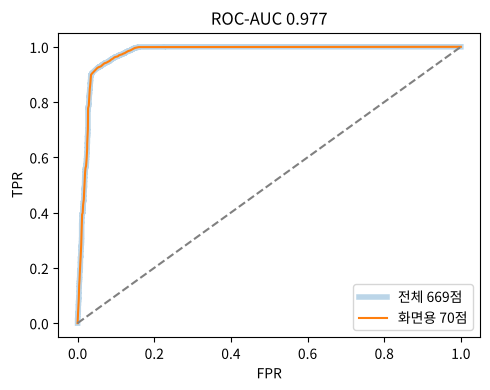

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

prob = mlp.predict_proba(x_test)
pred = (prob >= mlp.threshold).astype(int)
fpr, tpr, _ = roc_curve(y_test, prob)
scores = {'Accuracy': accuracy_score(y_test, pred), 'Recall · 이탈': recall_score(y_test, pred),
          'F1 · 이탈': f1_score(y_test, pred), 'Precision': precision_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, prob)}
print({k: f'{v * 100:.2f}%' for k, v in scores.items()})
print('혼동 행렬 :', confusion_matrix(y_test, pred).tolist(), '| 학습', len(x_train), '/ 평가', len(x_test))

# app.py 는 ROC 를 SVG 로 그릴 때 점을 최대 70개로 줄인다
idx = np.linspace(0, len(fpr) - 1, 70).astype(int) if len(fpr) > 70 else np.arange(len(fpr))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fpr, tpr, lw=4, alpha=0.3, label=f'전체 {len(fpr):,}점'); ax.plot(fpr[idx], tpr[idx], lw=1.5, label='화면용 70점')
ax.plot([0, 1], [0, 1], ls='--', c='gray'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(); ax.set_title(f'ROC-AUC {scores["ROC-AUC"]:.3f}')
plt.tight_layout(); plt.show()

- 저장된 팀 모델 · 같은 분할 → 정확도 **93.50%** · 재현율 93.30% · AUC 97.65% (README 93.8% · 94.0% · 97.6%)
- `app.py` 도 화면에 적어 두었듯 **학습 때의 분할이 기록돼 있지 않아**, 이 평가 분할이 학습에 안 쓰인 고객인지 확신할 수 없다 → 학습 노트북에서 테스트 인덱스를 저장해 두고 앱은 그 고객만 평가해야 한다

## 📝 점검 정리

| 항목 | `app.py` | 제안 |
|---|---|---|
| 포인트 4분위 | `rank(method='first')` → 같은 값 3,446명이 순서대로 두 구간에 갈림 | 값 기준 구간 + 경계값 표시 |
| 로그인 간격 | 정의 미확인 열을 '로그인 간격(일)' 로 표시 | 열 정의 확인 후 이름 붙이기 |
| 전처리기 | `.pkl` 을 열고 통계만 꺼내 NumPy 로 변환 | 통계를 JSON 으로 저장하면 버전 · pickle 문제 없음 |
| 입력 폼 | '보유 포인트 (만원)' | '보유 포인트(점)' |
| 성능 평가 | 현재 CSV 를 다시 80 : 20 | 학습 때 테스트 인덱스로만 |
| 모르는 값 | 원-핫 전부 0 으로 예측 | 처음 보는 범주는 먼저 걸러 경고 |
| 입력 범위 | 제한 없음 (거래 20만원도 예측) | 학습 데이터 범위로 `max_value` 제한 · 경고 |